# Pokémon Dataset — Extraction & Exploratory Data Analysis
**Phase 1 (Extraction) and Phase 2 (EDA) of the ETL pipeline**

## Dataset & sources
| source | file | rows |
|---|---|---|
| Original raw CSV (gens 1–7, dex 1–801) | `datasets/pokemon.csv` | 801 |
| PokeAPI (dex 802–1025) | cached JSON in `datasets/raw/` | 224 |
| Extended raw dataset used below | `datasets/pokemon_full.csv` | 1025 |

* `datasets/pokemon.csv` is the **raw source and is never modified** — every
  transformation writes to new files.
* The 224 Pokémon of generations VIII & IX (plus 8 gen-7 entries missing from
  the original file) were extracted from [PokeAPI](https://pokeapi.co) with
  `scripts/fetch_pokeapi.py` and mapped onto the original 41 columns with
  `scripts/build_dataset.py`. Raw API responses are kept in `datasets/raw/`.
* The mapping was **validated first**: 73 dex entries that already exist in the
  CSV were rebuilt from the API and diffed column by column (see §2.6).

Reproduce everything from the project root:
```bash
python scripts/fetch_pokeapi.py      # extract raw JSON (cached on disk)
python scripts/build_dataset.py      # validate + build datasets/pokemon_full.csv
```

> Run this notebook from the project root so the relative paths resolve.

In [1]:
# %matplotlib inline
import ast
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW_CSV = Path("datasets/pokemon.csv")
FULL_CSV = Path("datasets/pokemon_full.csv")
RAW_API = Path("datasets/raw")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

df = pd.read_csv(FULL_CSV)
print(f"{df.shape[0]} rows x {df.shape[1]} columns")
df.head(3)

1025 rows x 41 columns


,pokedex_number,name,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,against_grass,against_ground,against_ice,against_normal,against_poison,against_psychic,against_rock,against_steel,against_water,attack,base_egg_steps,base_happiness,base_total,capture_rate,classfication,defense,experience_growth,height_m,hp,japanese_name,percentage_male,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,1,Bulbasaur,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,1.0,2.0,1.0,1.0,2.0,1.0,1.0,0.5,49,5120,70,318,45,Seed Pokémon,49,1059860,0.7,45,Fushigidaneフシギダネ,88.1,65,65,45,grass,poison,6.9,1,0
1,2,Ivysaur,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,1.0,2.0,1.0,1.0,2.0,1.0,1.0,0.5,62,5120,70,405,45,Seed Pokémon,63,1059860,1.0,60,Fushigisouフシギソウ,88.1,80,80,60,grass,poison,13.0,1,0
2,3,Venusaur,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,1.0,2.0,1.0,1.0,2.0,1.0,1.0,0.5,100,5120,70,625,45,Seed Pokémon,123,1059860,2.0,80,Fushigibanaフシギバナ,88.1,122,120,80,grass,poison,100.0,1,0


In [2]:
# the original raw file is still untouched
raw = pd.read_csv(RAW_CSV)
print(f"raw source      : {raw.shape[0]} rows x {raw.shape[1]} columns")
print(f"extended dataset: {df.shape[0]} rows x {df.shape[1]} columns "
      f"(+{df.shape[0] - raw.shape[0]} rows from PokeAPI)")
print("columns added by the extension:",
      sorted(set(df.columns) - set(raw.columns)) or "none - same 41 columns")
print("column order changed:", list(df.columns[:4]), "...")

raw source      : 801 rows x 41 columns
extended dataset: 1025 rows x 41 columns (+224 rows from PokeAPI)
columns added by the extension: none - same 41 columns
column order changed: ['pokedex_number', 'name', 'abilities', 'against_bug'] ...


## 1. Basic dataset exploration

Shape, column names, data types, sample records, summary statistics and
unique values — before any cleaning takes place.

In [3]:
print("Rows:", df.shape[0], " Columns:", df.shape[1], "\n")
print("Column names:")
for i, col in enumerate(df.columns, 1):
    print(f"{i:3d}. {col}")

Rows: 1025  Columns: 41 

Column names:
  1. pokedex_number
  2. name
  3. abilities
  4. against_bug
  5. against_dark
  6. against_dragon
  7. against_electric
  8. against_fairy
  9. against_fight
 10. against_fire
 11. against_flying
 12. against_ghost
 13. against_grass
 14. against_ground
 15. against_ice
 16. against_normal
 17. against_poison
 18. against_psychic
 19. against_rock
 20. against_steel
 21. against_water
 22. attack
 23. base_egg_steps
 24. base_happiness
 25. base_total
 26. capture_rate
 27. classfication
 28. defense
 29. experience_growth
 30. height_m
 31. hp
 32. japanese_name
 33. percentage_male
 34. sp_attack
 35. sp_defense
 36. speed
 37. type1
 38. type2
 39. weight_kg
 40. generation
 41. is_legendary


In [4]:
# data types + completeness + cardinality in one table
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
overview

,dtype,non_null,missing,missing_%,n_unique
pokedex_number,int64,1025,0,0.0,1025
name,str,1025,0,0.0,1025
abilities,str,1025,0,0.0,628
against_bug,float64,1025,0,0.0,5
against_dark,float64,1025,0,0.0,5
against_dragon,float64,1025,0,0.0,4
against_electric,float64,1025,0,0.0,6
against_fairy,float64,1025,0,0.0,5
against_fight,float64,1025,0,0.0,6
against_fire,float64,1025,0,0.0,5


In [5]:
# sample records
display(df.head(4))
display(df.sample(5, random_state=42))

,pokedex_number,name,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,against_grass,against_ground,against_ice,against_normal,against_poison,against_psychic,against_rock,against_steel,against_water,attack,base_egg_steps,base_happiness,base_total,capture_rate,classfication,defense,experience_growth,height_m,hp,japanese_name,percentage_male,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,1,Bulbasaur,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,1.0,2.0,1.0,1.0,2.0,1.0,1.0,0.5,49,5120,70,318,45,Seed Pokémon,49,1059860,0.7,45,Fushigidaneフシギダネ,88.1,65,65,45,grass,poison,6.9,1,0
1,2,Ivysaur,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,1.0,2.0,1.0,1.0,2.0,1.0,1.0,0.5,62,5120,70,405,45,Seed Pokémon,63,1059860,1.0,60,Fushigisouフシギソウ,88.1,80,80,60,grass,poison,13.0,1,0
2,3,Venusaur,"['Overgrow', 'Chlorophyll']",1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,1.0,2.0,1.0,1.0,2.0,1.0,1.0,0.5,100,5120,70,625,45,Seed Pokémon,123,1059860,2.0,80,Fushigibanaフシギバナ,88.1,122,120,80,grass,poison,100.0,1,0
3,4,Charmander,"['Blaze', 'Solar Power']",0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,0.50,2.0,0.5,1.0,1.0,1.0,2.0,0.5,2.0,52,5120,70,309,45,Lizard Pokémon,43,1059860,0.6,39,Hitokageヒトカゲ,88.1,60,50,65,fire,NaN,8.5,1,0


,pokedex_number,name,abilities,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,against_grass,against_ground,against_ice,against_normal,against_poison,against_psychic,against_rock,against_steel,against_water,attack,base_egg_steps,base_happiness,base_total,capture_rate,classfication,defense,experience_growth,height_m,hp,japanese_name,percentage_male,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
527,528,Swoobat,"['Unaware', 'Klutz', 'Simple']",1.00,2.0,1.0,2.0,1.0,0.25,1.0,1.0,2.0,0.5,0.0,2.0,1.0,1.00,0.5,2.00,1.0,1.0,57,3840,70,425,45,Courting Pokémon,55,1000000,0.9,67,Kokoromoriココロモリ,50.0,77,55,114,psychic,flying,10.5,5,0
359,360,Wynaut,"['Shadow Tag', 'Telepathy']",2.00,2.0,1.0,1.0,1.0,0.50,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.00,0.5,1.00,1.0,1.0,23,5120,70,260,125,Bright Pokémon,48,1000000,0.6,95,Sohnanoソーナノ,50.0,23,48,23,psychic,NaN,14.0,3,0
447,448,Lucario,"['Steadfast', 'Inner Focus', 'Justified']",0.25,0.5,0.5,1.0,1.0,2.00,2.0,1.0,1.0,0.5,2.0,0.5,0.5,0.00,1.0,0.25,0.5,1.0,145,6400,70,625,45,Aura Pokémon,88,1059860,1.2,70,Lucarioルカリオ,88.1,140,70,112,fighting,steel,54.0,4,0
31,32,Nidoran♂,"['Poison Point', 'Rivalry', 'Hustle']",0.50,1.0,1.0,1.0,0.5,0.50,1.0,1.0,1.0,0.5,2.0,1.0,1.0,0.50,2.0,1.00,1.0,1.0,57,5120,70,273,235,Poison Pin Pokémon,40,1059860,0.5,46,Nidoran?ニドラン♂,100.0,40,40,50,poison,NaN,9.0,1,0
621,622,Golett,"['Iron Fist', 'Klutz', 'No Guard']",0.50,2.0,1.0,0.0,1.0,0.00,1.0,1.0,2.0,2.0,1.0,2.0,0.0,0.25,1.0,0.50,1.0,2.0,74,6400,70,303,190,Automaton Pokémon,50,1000000,1.0,59,Gobitゴビット,NaN,35,50,35,ground,ghost,92.0,5,0


In [6]:
# summary statistics (numeric columns only)
display(df.describe().T)
print("capture_rate is NOT in describe() because it is stored as text:")
df.capture_rate.head(3)

,count,mean,std,min,25%,50%,75%,max
pokedex_number,1025.0,5.130000e+02,296.036315,1.00,257.0,513.0,769.0,1025.0
against_bug,1025.0,1.007561e+00,0.632671,0.25,0.5,1.0,1.0,4.0
against_dark,1025.0,1.057073e+00,0.448425,0.25,1.0,1.0,1.0,4.0
against_dragon,1025.0,9.756098e-01,0.375508,0.00,1.0,1.0,1.0,2.0
against_electric,1025.0,1.044146e+00,0.633200,0.00,0.5,1.0,1.0,4.0
against_fairy,1025.0,1.092683e+00,0.545597,0.25,1.0,1.0,1.0,4.0
against_fight,1025.0,1.071220e+00,0.726555,0.00,0.5,1.0,2.0,4.0
against_fire,1025.0,1.137317e+00,0.677473,0.25,0.5,1.0,2.0,4.0
against_flying,1025.0,1.186341e+00,0.599201,0.25,1.0,1.0,1.0,4.0
against_ghost,1025.0,9.960976e-01,0.557254,0.00,1.0,1.0,1.0,4.0


capture_rate is NOT in describe() because it is stored as text:


0    45
1    45
2    45
Name: capture_rate, dtype: str

In [7]:
# unique values in the important columns
for col in ["generation", "type1", "is_legendary"]:
    vals = df[col].value_counts().sort_index()
    print(f"{col} ({df[col].nunique()} unique): {vals.to_dict()}")

print("\nnumber of unique values in the key columns:")
print(df[["pokedex_number", "name", "japanese_name", "classfication",
          "abilities", "type2", "percentage_male"]].nunique())

generation (9 unique): {1: 151, 2: 100, 3: 135, 4: 107, 5: 156, 6: 72, 7: 88, 8: 96, 9: 120}
type1 (18 unique): {'bug': 83, 'dark': 45, 'dragon': 37, 'electric': 59, 'fairy': 29, 'fighting': 40, 'fire': 66, 'flying': 9, 'ghost': 35, 'grass': 103, 'ground': 40, 'ice': 31, 'normal': 118, 'poison': 42, 'psychic': 60, 'rock': 58, 'steel': 36, 'water': 134}
is_legendary (2 unique): {0: 927, 1: 98}

number of unique values in the key columns:
pokedex_number     1025
name               1025
japanese_name      1025
classfication       717
abilities           628
type2                18
percentage_male       9
dtype: int64


In [8]:
# all 18 types appear as primary type, none outside the official chart
OFFICIAL_TYPES = {"bug", "dark", "dragon", "electric", "fairy", "fighting",
                  "fire", "flying", "ghost", "grass", "ground", "ice",
                  "normal", "poison", "psychic", "rock", "steel", "water"}
print("unexpected type1 values:", set(df.type1) - OFFICIAL_TYPES or "none")
print("unexpected type2 values:", set(df.type2.dropna()) - OFFICIAL_TYPES or "none")
print("dual-type Pokémon:", int(df.type2.notna().sum()),
      f"({df.type2.notna().mean():.0%})  |  single-type:",
      int(df.type2.isna().sum()))

unexpected type1 values: none
unexpected type2 values: none
dual-type Pokémon: 542 (53%)  |  single-type: 483


## 2. Data quality analysis

Missing values, duplicates, wrong data types, invalid/inconsistent values,
outliers, unexpected categories and formatting problems.

In [9]:
# --- missing / null values ------------------------------------------------
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "of_total_%": (df.isna().mean() * 100).round(1),
}).query("missing > 0").sort_values("missing", ascending=False)
display(missing)

print("\ntype2 and percentage_male are *structural* blanks:",
      "\n  * a Pokémon without a second type has no type2,",
      "\n  * genderless Pokémon (Porygon, Magnemite, Ultra Beasts ...) have no ratio.",
      "\nheight_m / weight_kg blanks are a real defect - see section 2.4.")

,missing,of_total_%
type2,483,47.1
percentage_male,155,15.1
height_m,20,2.0
weight_kg,20,2.0



type2 and percentage_male are *structural* blanks: 
  * a Pokémon without a second type has no type2, 
  * genderless Pokémon (Porygon, Magnemite, Ultra Beasts ...) have no ratio. 
height_m / weight_kg blanks are a real defect - see section 2.4.


In [10]:
# --- duplicate records ----------------------------------------------------
print("fully duplicated rows :", int(df.duplicated().sum()))
print("duplicate names       :", int(df.duplicated('name').sum()))
print("duplicate dex numbers :", int(df.duplicated('pokedex_number').sum()))
print("dex range covered     :", int(df.pokedex_number.min()), "-",
      int(df.pokedex_number.max()),
      "| gaps:", sorted(set(range(1, 1026)) - set(df.pokedex_number)) or "none")

fully duplicated rows : 0
duplicate names       : 0
duplicate dex numbers : 0
dex range covered     : 1 - 1025 | gaps: none


In [11]:
# --- data types -----------------------------------------------------------
print(df.dtypes.value_counts(), "\n")
print("columns that look numeric but are stored as text:")
for col in df.columns:
    coerced = pd.to_numeric(df[col], errors="coerce")
    if df[col].dtype != "float64" and df[col].dtype != "int64" \
            and coerced.notna().sum() >= len(df) * 0.9:
        bad = df.loc[coerced.isna() & df[col].notna(), col]
        print(f"  {col}: {coerced.notna().sum()}/{len(df)} convertible -> "
              f"exceptions: {bad.unique()[:3].tolist()}")

float64    21
int64      13
str         7
Name: count, dtype: int64 

columns that look numeric but are stored as text:
  capture_rate: 1024/1025 convertible -> exceptions: ['30 (Meteorite)255 (Core)']


In [12]:
# abilities / japanese_name are stringified structures, not plain text
print("abilities example :", df.abilities.iloc[0])
print("parsed            :", ast.literal_eval(df.abilities.iloc[0]))
print("japanese_name     :", df.japanese_name.iloc[0], "= romaji + japanese script")

abilities example : ['Overgrow', 'Chlorophyll']
parsed            : ['Overgrow', 'Chlorophyll']
japanese_name     : Fushigidaneフシギダネ = romaji + japanese script


### 2.1 — `against_*` columns vs. the official type chart

The 18 `against_*` columns should equal *the damage an attacker of that type
deals to this Pokémon* — i.e. the type chart applied to **both** defensive
types (dual types multiply). The chart below is rebuilt from the cached
PokeAPI type data, so nothing is hard-coded.

In [13]:
# rebuild the type chart from the raw API cache
chart = {}
for path in sorted(RAW_API.glob("type_*.json")):
    name = path.stem.split("_", 1)[1]
    rel = json.loads(path.read_text())["damage_relations"]
    multipliers = {d["name"]: 2.0 for d in rel["double_damage_to"]}
    multipliers.update({d["name"]: 0.5 for d in rel["half_damage_to"]})
    multipliers.update({d["name"]: 0.0 for d in rel["no_damage_to"]})
    chart[name] = multipliers


def expected_against(types):
    cells = {}
    for atk in chart:
        col = "against_fight" if atk == "fighting" else f"against_{atk}"
        value = 1.0
        for defence in types:          # dual types multiply
            value *= chart[atk].get(defence, 1.0)
        cells[col] = value
    return cells


problems = []
for row in df.itertuples():
    types = [row.type1] + ([row.type2] if isinstance(row.type2, str) else [])
    for col, expected in expected_against(types).items():
        actual = float(getattr(row, col))
        if abs(actual - expected) > 1e-9:
            problems.append([row.pokedex_number, row.name, col, actual, expected])

bad_against = pd.DataFrame(problems, columns=["dex", "name", "column", "csv_value", "type_chart_value"])
print(f"{len(bad_against)} mismatching cells across {bad_against.name.nunique()} Pokémon")
print(f"(checked {len(df) * 18} cells = 1025 Pokémon x 18 attacking types)")
bad_against.groupby("name").size().sort_values(ascending=False)

95 mismatching cells across 16 Pokémon
(checked 18450 cells = 1025 Pokémon x 18 attacking types)


name
Darmanitan    9
Marowak       9
Shaymin       9
Muk           7
Grimer        7
Dugtrio       5
Meowth        5
Diglett       5
Ninetales     5
Persian       5
Rattata       5
Raticate      5
Sandslash     5
Sandshrew     5
Vulpix        5
Raichu        4
dtype: int64

In [14]:
# the CSV says these are dual-typed but gives single-type effectiveness values
display(bad_against[bad_against.name.isin(["Rattata", "Meowth", "Marowak"])].head(12))
# ... and the same rows carry regional (Alolan) types with base-form measurements
display(df.loc[df.name.isin(["Rattata", "Meowth", "Vulpix", "Raichu"]),
               ["pokedex_number", "name", "type1", "type2", "height_m", "weight_kg"]])

,dex,name,column,csv_value,type_chart_value
0,19,Rattata,against_bug,1.0,2.0
1,19,Rattata,against_dark,1.0,0.5
2,19,Rattata,against_fairy,1.0,2.0
3,19,Rattata,against_fight,2.0,4.0
4,19,Rattata,against_psychic,1.0,0.0
44,52,Meowth,against_bug,1.0,2.0
45,52,Meowth,against_dark,1.0,0.5
46,52,Meowth,against_fairy,1.0,2.0
47,52,Meowth,against_fight,2.0,4.0
48,52,Meowth,against_psychic,1.0,0.0


,pokedex_number,name,type1,type2,height_m,weight_kg
18,19,Rattata,normal,dark,NaN,NaN
25,26,Raichu,electric,electric,NaN,NaN
36,37,Vulpix,fire,ice,NaN,NaN
51,52,Meowth,normal,dark,NaN,NaN


In [15]:
# --- inconsistent / invalid values ----------------------------------------
# 1) type2 identical to type1 (impossible for a real Pokémon)
same = df[df.type2.notna() & (df.type1 == df.type2)]
print("type2 == type1:", same.name.tolist(), "\n")

# 2) percentage_male outside the values the game actually uses
STANDARD_RATIOS = {0.0, 12.5, 25.0, 37.5, 50.0, 62.5, 75.0, 87.5, 100.0}
odd_ratio = df[df.percentage_male.notna() & ~df.percentage_male.isin(STANDARD_RATIOS)]
print("non-standard gender ratios in the CSV:")
print(odd_ratio.percentage_male.value_counts().to_dict())
print("  -> the original file uses 88.1 / 75.4 / 24.6 / 11.2 where the games",
      "\n     use 87.5 / 75 / 25 / 12.5. Rows 1-801 are affected;",
      "\n     the PokeAPI rows use the correct values.")
print("rows with a non-standard value:", len(odd_ratio), "\n")

# 3) capture_rate should be an integer
not_int = df[~df.capture_rate.astype(str).str.fullmatch(r"\d+")]
print("capture_rate values that are not a plain integer:")
print(not_int[["pokedex_number", "name", "capture_rate"]].to_string(index=False))

type2 == type1: ['Raichu', 'Diglett', 'Dugtrio', 'Grimer', 'Muk', 'Shaymin', 'Darmanitan'] 

non-standard gender ratios in the CSV:
{88.1: 111, 24.6: 24, 75.4: 19, 11.2: 2}
  -> the original file uses 88.1 / 75.4 / 24.6 / 11.2 where the games 
     use 87.5 / 75 / 25 / 12.5. Rows 1-801 are affected; 
     the PokeAPI rows use the correct values.
rows with a non-standard value: 156 

capture_rate values that are not a plain integer:
 pokedex_number   name             capture_rate
            774 Minior 30 (Meteorite)255 (Core)


In [16]:
# --- unexpected categories ------------------------------------------------
print("is_legendary values :", sorted(df.is_legendary.unique()))
print("generation values    :", sorted(df.generation.unique()))
print("type1 values         :", df.type1.nunique(), "of 18 official types")
print("rows per generation  :", df.generation.value_counts().sort_index().to_dict())
print("\nlegendary flag also contains mythicals (Mew, Deoxys, Keldeo ...),",
      "\nwhich is how the original file was built:",
      df.loc[df.name.isin(["Mew", "Deoxys", "Keldeo"]), ["name", "is_legendary"]].to_string(index=False))

is_legendary values : [np.int64(0), np.int64(1)]
generation values    : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
type1 values         : 18 of 18 official types
rows per generation  : {1: 151, 2: 100, 3: 135, 4: 107, 5: 156, 6: 72, 7: 88, 8: 96, 9: 120}

legendary flag also contains mythicals (Mew, Deoxys, Keldeo ...), 
which is how the original file was built:   name  is_legendary
   Mew             1
Deoxys             1
Keldeo             1


### 2.2 — Outliers (IQR method)

Values outside `Q1 − 1.5·IQR` / `Q3 + 1.5·IQR`. Most are legitimate — Pokémon
like Wailord and Celesteela are meant to be extreme — but they are worth
listing before deciding what to do with them.

In [17]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


numeric = ["height_m", "weight_kg", "hp", "attack", "defense",
           "sp_attack", "sp_defense", "speed", "base_total", "base_egg_steps"]
rows = []
for col in numeric:
    lo, hi = iqr_bounds(df[col])
    out = df[(df[col] < lo) | (df[col] > hi)]
    rows.append({"column": col, "low": lo, "high": hi,
                 "outliers": len(out),
                 "max example": df.loc[df[col].idxmax(), "name"] + f" ({df[col].max()})"})
outliers = pd.DataFrame(rows)
outliers

,column,low,high,outliers,max example
0,height_m,-1.00,3.00,40,Eternatus (20.0)
1,weight_kg,-85.25,164.75,101,Cosmoem (999.9)
2,hp,-2.50,137.50,19,Blissey (255)
3,attack,-12.50,167.50,5,Heracross (185)
4,defense,-10.00,150.00,13,Steelix (230)
5,sp_attack,-16.50,155.50,13,Mewtwo (194)
6,sp_defense,-8.50,147.50,11,Shuckle (230)
7,speed,-22.50,157.50,3,Regieleki (200)
8,base_total,40.00,800.00,0,Mewtwo (780)
9,base_egg_steps,3200.00,8320.00,222,Mewtwo (30720)


In [18]:
# example: who are the extreme ones?
display(df.nlargest(5, "weight_kg")[["name", "weight_kg", "type1", "generation"]])
display(df.nlargest(5, "height_m")[["name", "height_m", "type1", "generation"]])
display(df.nlargest(5, "hp")[["name", "hp", "is_legendary"]])

,name,weight_kg,type1,generation
789,Cosmoem,999.9,psychic,7
796,Celesteela,999.9,steel,7
382,Groudon,950.0,ground,3
889,Eternatus,950.0,poison,8
749,Mudsdale,920.0,ground,7


,name,height_m,type1,generation
889,Eternatus,20.0,poison,8
320,Wailord,14.5,water,3
976,Dondozo,12.0,water,9
207,Steelix,9.2,steel,2
796,Celesteela,9.2,steel,7


,name,hp,is_legendary
241,Blissey,255,0
112,Chansey,250,0
798,Guzzlord,223,1
717,Zygarde,216,1
894,Regidrago,200,1


### 2.3 — Formatting & consistency issues

Text fields that disagree with their own official spellings.

In [19]:
# 1) ability names: compare every token with the official ability index
idx = json.loads((RAW_API / "ability_index.json").read_text())
official = {r["name"] for r in idx["results"]}          # slug form, e.g. compound-eyes
by_norm = {s.replace("-", "").replace(" ", ""): s for s in official}

spelling, whitespace = {}, set()
for value in df.abilities:
    for token in ast.literal_eval(value):
        if token != token.strip():
            whitespace.add(repr(token))
        candidate = by_norm.get(token.strip().replace("-", "").replace(" ", "").lower())
        if candidate and token.strip().lower() not in {candidate,
                                                       candidate.replace("-", " ").lower()}:
            spelling[token] = candidate
print("ability names that differ from the official spelling:", spelling)
print("ability names with stray whitespace:", whitespace or "none")

# 2) columns with typos / free-form labels
print("\nmisspelled column name:", [c for c in df.columns if c == "classfication"])
print("names with punctuation:", df.loc[df.name.str.contains(r"[^A-Za-z0-9 \- ']"), "name"].tolist()[:12])
print("japanese_name entries with a form label:",
      df.japanese_name.str.contains("\(").sum(), "rows")

ability names that differ from the official spelling: {'Compoundeyes': 'compound-eyes', 'Lightningrod': 'lightning-rod'}
ability names with stray whitespace: {"'Wonder Skin '"}

misspelled column name: ['classfication']
names with punctuation: ['Nidoran♀', 'Nidoran♂', 'Mr. Mime', 'Mime Jr.', 'Flabébé', 'Type: Null', 'Mr. Rime']
japanese_name entries with a form label: 13 rows


<>:22: SyntaxWarning: invalid escape sequence '\('
<>:22: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_8854/1873831282.py:22: SyntaxWarning: invalid escape sequence '\('
  df.japanese_name.str.contains("\(").sum(), "rows")


In [20]:
# 3) rows whose height/weight are missing although every Pokémon has both
missing_size = df[df.height_m.isna() | df.weight_kg.isna()]
print(f"{len(missing_size)} rows without height/weight:")
missing_size[["pokedex_number", "name", "type1", "type2", "generation"]].to_string(index=False)

20 rows without height/weight:


' pokedex_number      name    type1    type2  generation\n             19   Rattata   normal     dark           1\n             20  Raticate   normal     dark           1\n             26    Raichu electric electric           1\n             27 Sandshrew   ground      ice           1\n             28 Sandslash   ground      ice           1\n             37    Vulpix     fire      ice           1\n             38 Ninetales     fire      ice           1\n             50   Diglett   ground   ground           1\n             51   Dugtrio   ground   ground           1\n             52    Meowth   normal     dark           1\n             53   Persian   normal     dark           1\n             74   Geodude     rock   ground           1\n             75  Graveler     rock   ground           1\n             76     Golem     rock   ground           1\n             88    Grimer   poison   poison           1\n             89       Muk   poison   poison           1\n            103 Exeggutor    g

### 2.4 — Validation of the PokeAPI field mapping

`scripts/build_dataset.py` rebuilt 73 dex entries that already exist in the raw
CSV and diffed every column. The remaining differences are **defects in the
original file**, not in the mapping — this is the list Phase 3 has to clean:

| column | finding |
|---|---|
| `percentage_male` | 15 rows use 88.1 instead of 87.5 (and similar) |
| `attack`, `sp_attack`, `base_total`, ... | mega/regional-form stats merged into the base row (Charizard `634` = Mega Charizard X) |
| `type2`, `height_m`, `weight_kg` | Alolan-form rows: duplicated `type2`, empty size |
| `abilities` | form-specific abilities (`Surge Surfer`) and bad spellings (`Compoundeyes`) |
| `classfication`, `japanese_name` | free-form wording / form labels |
| `capture_rate` | `30 (Meteorite)255 (Core)` (Minior), Necrozma `3` vs API `255` |

Re-run it any time with `python scripts/build_dataset.py`.

## 3. Exploratory analysis

Distribution of Pokémon across generations and types, base-stat trends,
legendaries, physical vs. special attackers, size, catch rates and abilities.

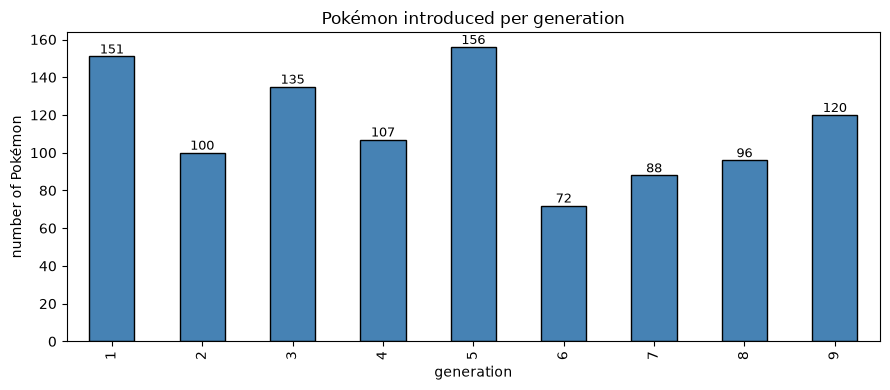

In [21]:
# --- Pokémon per generation ----------------------------------------------
ax = df.generation.value_counts().sort_index().plot(
    kind="bar", figsize=(9, 4), color="steelblue", edgecolor="black")
ax.set_title("Pokémon introduced per generation")
ax.set_xlabel("generation")
ax.set_ylabel("number of Pokémon")
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()

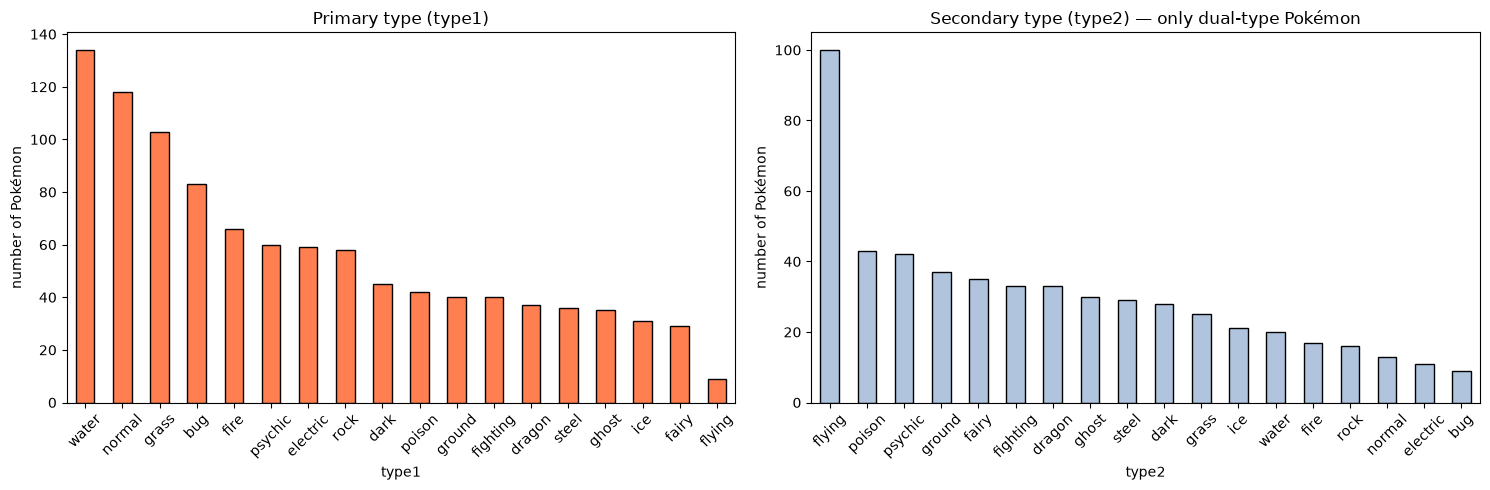

In [22]:
# --- primary / secondary type distribution --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df.type1.value_counts().plot(kind="bar", ax=axes[0], color="coral", edgecolor="black")
axes[0].set_title("Primary type (type1)")
axes[0].set_ylabel("number of Pokémon")
axes[0].tick_params(axis="x", rotation=45)

df.type2.value_counts().plot(kind="bar", ax=axes[1], color="lightsteelblue", edgecolor="black")
axes[1].set_title("Secondary type (type2) — only dual-type Pokémon")
axes[1].set_ylabel("number of Pokémon")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()

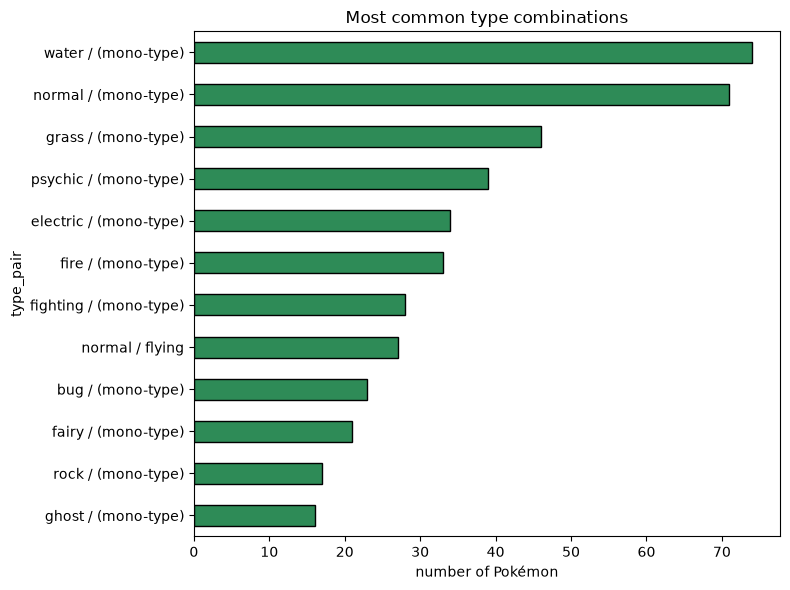

In [23]:
# --- most common type combinations ----------------------------------------
df["type_pair"] = df.type1 + " / " + df.type2.fillna("(mono-type)")
ax = df.type_pair.value_counts().head(12).sort_values().plot(
    kind="barh", figsize=(8, 6), color="seagreen", edgecolor="black")
ax.set_title("Most common type combinations")
ax.set_xlabel("number of Pokémon")
plt.tight_layout()

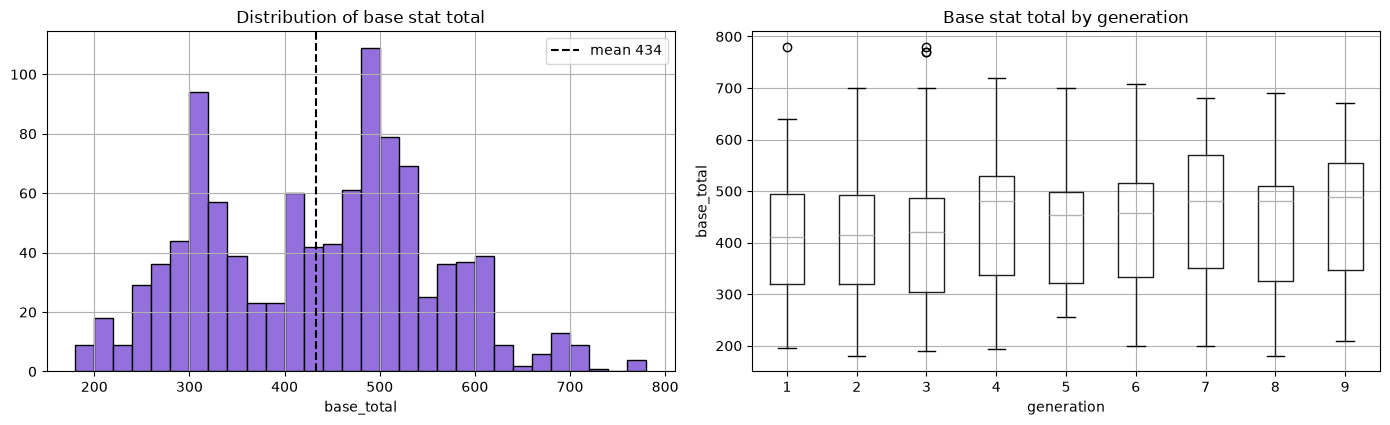

In [24]:
# --- base stat total: distribution and trend over generations -------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

df.base_total.hist(bins=30, ax=axes[0], color="mediumpurple", edgecolor="black")
axes[0].axvline(df.base_total.mean(), color="black", ls="--",
                label=f"mean {df.base_total.mean():.0f}")
axes[0].set_title("Distribution of base stat total")
axes[0].set_xlabel("base_total")
axes[0].legend()

df.boxplot(column="base_total", by="generation", ax=axes[1])
axes[1].set_title("Base stat total by generation")
axes[1].set_xlabel("generation")
axes[1].set_ylabel("base_total")
fig.suptitle("")
plt.tight_layout()

In [25]:
# average power creep per generation
by_gen = df.groupby("generation").agg(
    pokemons=("name", "count"),
    avg_base_total=("base_total", "mean"),
    avg_hp=("hp", "mean"),
    avg_speed=("speed", "mean"),
).round(1)
by_gen

,pokemons,avg_base_total,avg_hp,avg_speed
generation,,,,
1,151,416.3,64.3,70.2
2,100,413.2,71.0,61.6
3,135,420.0,65.7,63.6
4,107,451.2,73.1,70.1
5,156,427.0,70.3,66.5
6,72,437.6,71.1,66.7
7,88,455.1,71.1,65.6
8,96,439.2,72.8,68.9
9,120,457.4,77.4,75.4


,pokemons,avg_base_total,avg_attack,avg_sp_attack
type1,,,,
dragon,37,510.4,103.6,84.7
steel,36,486.8,93.6,74.8
dark,45,461.4,88.7,74.9
psychic,60,455.0,64.6,92.1
fire,66,451.7,82.0,86.6
rock,58,447.4,89.2,62.4
fighting,40,446.6,104.6,54.3
fairy,29,442.3,67.5,77.8
electric,59,441.1,73.3,86.8


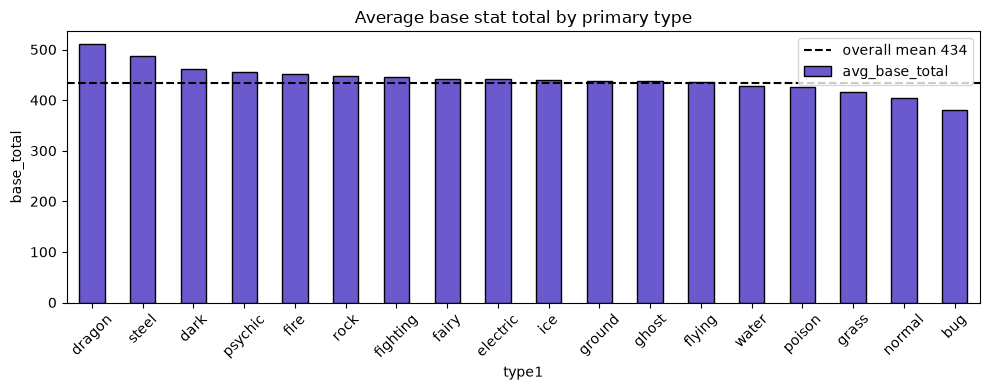

In [26]:
# --- which primary type is the strongest? ---------------------------------
by_type = (df.groupby("type1")
             .agg(pokemons=("name", "count"),
                  avg_base_total=("base_total", "mean"),
                  avg_attack=("attack", "mean"),
                  avg_sp_attack=("sp_attack", "mean"))
             .sort_values("avg_base_total", ascending=False)
             .round(1))
display(by_type)

ax = by_type.avg_base_total.plot(kind="bar", figsize=(10, 4),
                                 color="slateblue", edgecolor="black")
ax.axhline(df.base_total.mean(), color="black", ls="--",
           label=f"overall mean {df.base_total.mean():.0f}")
ax.set_title("Average base stat total by primary type")
ax.set_ylabel("base_total")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.tight_layout()

,pokedex_number,name,type1,type2,generation,base_total,is_legendary
149,150,Mewtwo,psychic,NaN,1,780,1
383,384,Rayquaza,dragon,flying,3,780,1
381,382,Kyogre,water,NaN,3,770,1
382,383,Groudon,ground,NaN,3,770,1
492,493,Arceus,normal,NaN,4,720,1
717,718,Zygarde,dragon,ground,6,708,1
247,248,Tyranitar,rock,dark,2,700,0
372,373,Salamence,dragon,flying,3,700,0
375,376,Metagross,steel,psychic,3,700,0
379,380,Latias,dragon,psychic,3,700,1


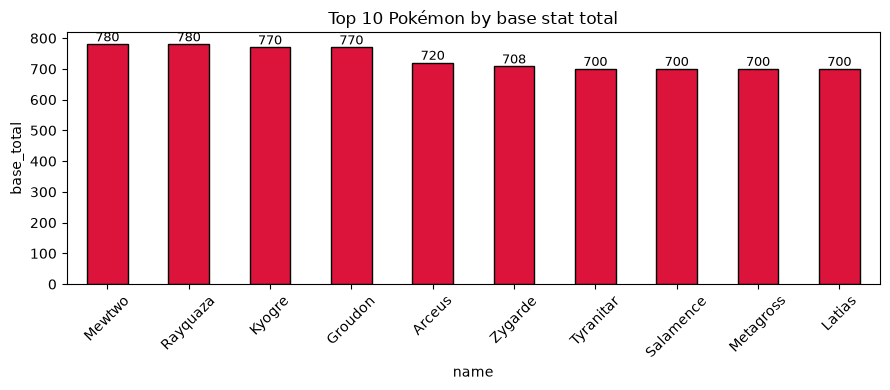

In [27]:
# --- strongest Pokémon -----------------------------------------------------
top = df.nlargest(10, "base_total")[
    ["pokedex_number", "name", "type1", "type2", "generation", "base_total", "is_legendary"]]
ax = top.set_index("name").base_total.plot(kind="bar", figsize=(9, 4),
                                           color="crimson", edgecolor="black")
ax.set_title("Top 10 Pokémon by base stat total")
ax.set_ylabel("base_total")
ax.tick_params(axis="x", rotation=45)
for p in ax.patches:
    ax.annotate(str(int(p.get_height())), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
top

In [28]:
# --- legendary vs. regular -------------------------------------------------
compare = df.groupby("is_legendary")[["hp", "attack", "defense",
                                      "sp_attack", "sp_defense", "speed",
                                      "base_total"]].mean().round(1)
compare.index = ["regular", "legendary/mythical"]
display(compare)
print(f"legendary share: {df.is_legendary.mean():.1%}  ({int(df.is_legendary.sum())} Pokémon)")
print("legendary average base stat total is",
      f"{compare.loc['legendary/mythical', 'base_total'] / compare.loc['regular', 'base_total']:.2f}x",
      "the regular average")

,hp,attack,defense,sp_attack,sp_defense,speed,base_total
regular,67.7,76.1,71.1,68.0,68.2,64.7,415.7
legendary/mythical,95.7,107.7,97.4,106.9,97.6,96.8,602.0


legendary share: 9.6%  (98 Pokémon)
legendary average base stat total is 1.45x the regular average


{'physical': 525, 'special': 355, 'balanced': 145}


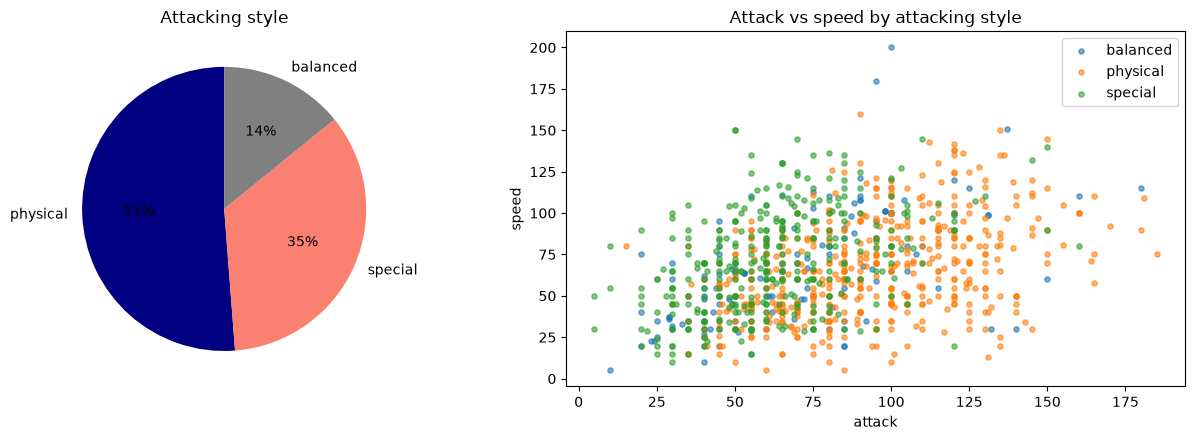

In [29]:
# --- calculated column: physical or special attacker ----------------------
df["main_offense"] = np.where(df.attack > df.sp_attack, "physical",
                       np.where(df.sp_attack > df.attack, "special", "balanced"))
print(df.main_offense.value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
df.main_offense.value_counts().plot(kind="pie", ax=axes[0], autopct="%1.0f%%",
                                    colors=["navy", "salmon", "gray"], startangle=90)
axes[0].set_title("Attacking style")
axes[0].set_ylabel("")

for style, group in df.groupby("main_offense"):
    axes[1].scatter(group.attack, group.speed, s=14, alpha=0.6, label=style)
axes[1].set_xlabel("attack")
axes[1].set_ylabel("speed")
axes[1].set_title("Attack vs speed by attacking style")
axes[1].legend()
plt.tight_layout()

strongest correlations with base_total:
attack        0.73
sp_attack     0.72
sp_defense    0.71
hp            0.64
defense       0.64
speed         0.56
height_m      0.50
weight_kg     0.45


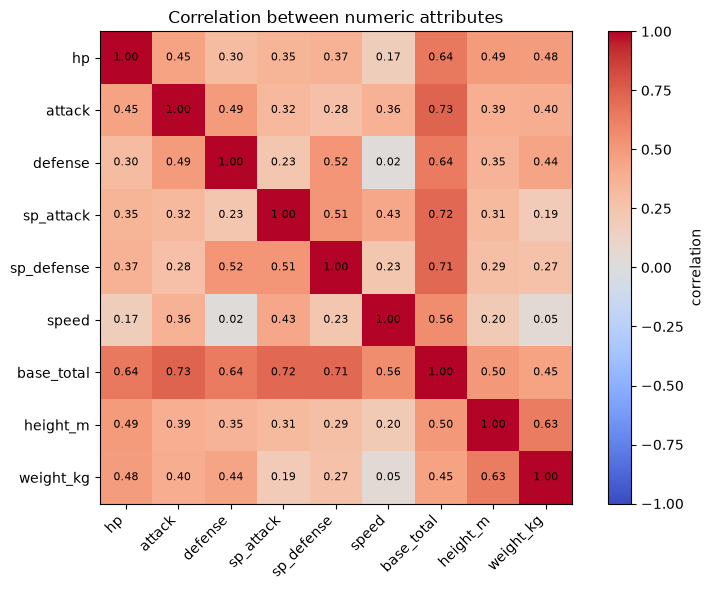

In [30]:
# --- correlations ----------------------------------------------------------
num_cols = ["hp", "attack", "defense", "sp_attack", "sp_defense", "speed",
            "base_total", "height_m", "weight_kg"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)), corr.columns)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="correlation")
ax.set_title("Correlation between numeric attributes")
plt.tight_layout()

print("strongest correlations with base_total:")
print(corr.base_total.drop("base_total").sort_values(ascending=False).round(2).to_string())

heaviest : [['Cosmoem', 999.9], ['Celesteela', 999.9], ['Groudon', 950.0]]
tallest  : [['Eternatus', 20.0], ['Wailord', 14.5], ['Dondozo', 12.0]]
smallest : [['Gastly', 0.1], ['Haunter', 0.1], ['Flabébé', 0.1]]


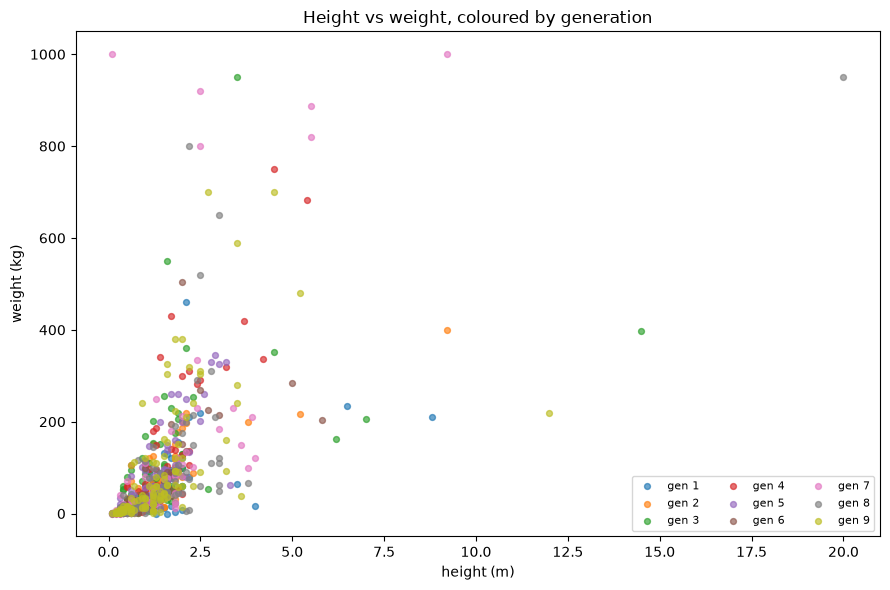

In [31]:
# --- size: height vs weight ------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
for gen, group in df.groupby("generation"):
    ax.scatter(group.height_m, group.weight_kg, s=18, alpha=0.65, label=f"gen {gen}")
ax.set_xlabel("height (m)")
ax.set_ylabel("weight (kg)")
ax.set_title("Height vs weight, coloured by generation")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()

print("heaviest :", df.nlargest(3, "weight_kg")[["name", "weight_kg"]].values.tolist())
print("tallest  :", df.nlargest(3, "height_m")[["name", "height_m"]].values.tolist())
print("smallest :", df.nsmallest(3, "weight_kg")[["name", "weight_kg"]].values.tolist())

rows where capture_rate could not be parsed:


' pokedex_number   name             capture_rate\n            774 Minior 30 (Meteorite)255 (Core)'

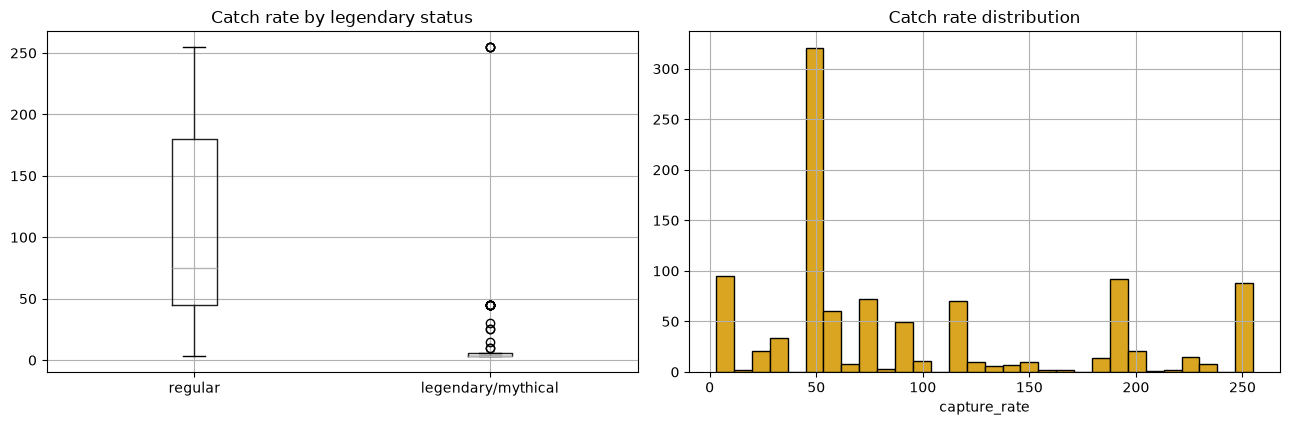

In [32]:
# --- catch rate: legendary vs regular -------------------------------------
rate = pd.to_numeric(df.capture_rate, errors="coerce")   # Minior's mixed value -> NaN
tmp = pd.DataFrame({"capture_rate": rate, "is_legendary": df.is_legendary})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tmp.boxplot(column="capture_rate", by="is_legendary", ax=axes[0])
axes[0].set_xticklabels(["regular", "legendary/mythical"])
axes[0].set_title("Catch rate by legendary status")
axes[0].set_xlabel("")
rate.hist(bins=30, ax=axes[1], color="goldenrod", edgecolor="black")
axes[1].set_title("Catch rate distribution")
axes[1].set_xlabel("capture_rate")
fig.suptitle("")
plt.tight_layout()

print("rows where capture_rate could not be parsed:")
df.loc[rate.isna(), ["pokedex_number", "name", "capture_rate"]].to_string(index=False)

genderless rows (blank): 155
value counts: {0.0: 37, 11.2: 2, 24.6: 24, 25.0: 1, 50.0: 630, 75.4: 19, 87.5: 20, 88.1: 111, 100.0: 26}


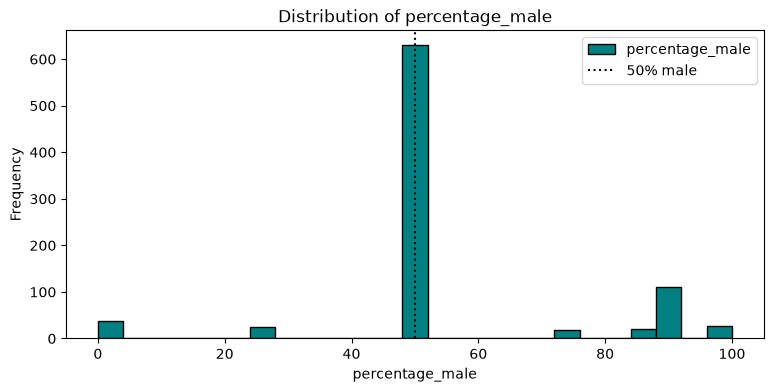

In [33]:
# --- gender ratios ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4))
df.percentage_male.plot(kind="hist", bins=25, ax=ax, color="teal", edgecolor="black")
ax.axvline(50, color="black", ls=":", label="50% male")
ax.set_title("Distribution of percentage_male")
ax.set_xlabel("percentage_male")
ax.legend()
print("genderless rows (blank):", int(df.percentage_male.isna().sum()))
print("value counts:", df.percentage_male.value_counts().sort_index().to_dict())

291 distinct abilities over 1025 Pokémon


Sturdy         45
Swift Swim     44
Keen Eye       40
Chlorophyll    37
Intimidate     36
Inner Focus    35
Levitate       33
Swarm          31
Gluttony       31
Sheer Force    30
Name: count, dtype: int64

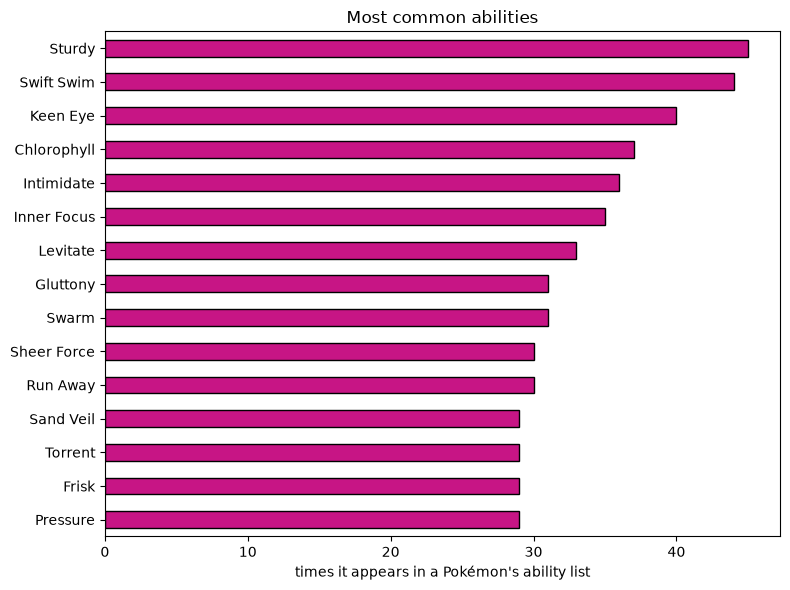

In [34]:
# --- most common abilities -------------------------------------------------
counter = Counter()
for value in df.abilities:
    counter.update(ast.literal_eval(value))
abilities = pd.Series(counter, name="count").sort_values(ascending=False)

print(f"{len(abilities)} distinct abilities over {len(df)} Pokémon")
ax = abilities.head(15).sort_values().plot(kind="barh", figsize=(8, 6),
                                           color="mediumvioletred", edgecolor="black")
ax.set_title("Most common abilities")
ax.set_xlabel("times it appears in a Pokémon's ability list")
plt.tight_layout()
abilities.head(10)

## 4. EDA summary

### Exploratory findings
1. **Generations VIII & IX added 216 Pokémon** (96 + 120), taking the national
   Pokédex to 1025; generation V is still the largest single generation (156),
   followed by IX (120).
2. **Water (134) and Normal (118) are the most common primary types**, Flying
   is almost always a secondary type (9 as `type1`), and 52% of all Pokémon
   are dual-typed.
3. **Average base stat total rises with the generations** — from ≈413 (gen II)
   to ≈457 (gen IX) — a clear "power creep"; dragon and steel are on average
   the strongest primary types.
4. **Legendary/mythical Pokémon (98, 9.6%) average ~602 base stats vs ~416
   for regular Pokémon**, with every stat category higher.
5. **`base_total` tracks the offensive stats** (attack 0.73, sp_attack 0.72,
   sp_defense 0.71), attack correlates only weakly with speed (0.36), and size
   has a moderate — not decisive — link to power (height 0.50 / weight 0.45).
6. **Catch rate cleanly separates legendaries** (mostly ≤10) from regular
   Pokémon, and `Sturdy`/`Swift Swim`/`Keen Eye` are the most common abilities.

### Data-quality issues found (input for Phase 3 cleaning)
| # | issue | scope |
|---|---|---|
| 1 | `percentage_male` uses 88.1 / 75.4 / 24.6 / 11.2 instead of 87.5 / 75 / 25 / 12.5 | 156 rows |
| 2 | mega/regional-form stats merged into base rows (e.g. Charizard `base_total` 634 = Mega Charizard, Alolan Raichu stats) | several rows in gens 1–7 |
| 3 | Alolan-form data mixed in: duplicated `type2`, empty `height_m`/`weight_kg` | 20 rows |
| 4 | `against_*` disagrees with `type1`/`type2` (form rows) | 95 cells / 16 Pokémon |
| 5 | `capture_rate` stored as text with a mixed value (`30 (Meteorite)255 (Core)`) | 1 column, 1 row |
| 6 | ability spelling (`Compoundeyes`, `Lightningrod`, trailing space) | few rows |
| 7 | column name typo `classfication`, `japanese_name` form labels | 2 columns |
| 8 | `type2` structurally blank for 483 single-type rows, `percentage_male` blank for 155 genderless | expected, keep as null |
| 9 | outliers (Wailord/Celesteela size, Blissey HP) | legitimate, document |